# Flujo y transporte reactivo de 2 especies en equilibrio con el yeso en 1D. 

**Descripción**.

En esta notebook se modela el flujo y transporte reactivo de la componente $U = c_1 - c_2$ donde $c_1 = Ca^{2+}$ y $c_2 = SO_4^{2-}$. La estrategia de solución consiste en resolver el flujo con GWF de MODFLOW 6, discretizar el transporte con diferencias finitas usando un códgio en Python (DFC) para generar las matrices de coeficientes, calcular las razones de mezcla ($\lambda$'s) y finalmente resolver el transporte reactivo con WMA usando un código en Fortran.

<a href="https://github.com/luiggix/RTWMA">RTWMA</a> © 2024-2026 by <a href="https://www.geofisica.unam.mx">IGF-UNAM</a> is licensed under <a href="https://creativecommons.org/licenses/by-nc/4.0/">CC BY-NC 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/nc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">

# Planteamiento del problema.

El dominio es una columna 1D de longitud $L = 30 \text{ (m)}$, en dirección $x$, representando un acuífero de espesor y ancho unitarios. Sobre este dominio ocurren dos procesos:

- Flujo de agua subterránea, gobernado por la carga hidráulica $h(x,t)$.
- Transporte reactivo, gobernado por un conjunto de ecuaciones que expresan el balance de masa de las especies químicas y las reacciones químicas. 

El problema se va a resolver en un periodo de $40$ días, con un paso de tiempo constante de $1$ día ($40$ pasos de tiempo).

## Modelo de flujo de agua subterránea.

Para un acuífero 1D, confinado con conductividad hidráulica $K_x$ y
coeficiente de almacenamiento específico $S_s$, la ecuación de flujo es:

$$
S_s \frac{\partial h}{\partial t} = \frac{\partial}{\partial x}
\left( K_x \frac{\partial h}{\partial x} \right) + q_s(x,t)
$$

donde $q_s(x,t)$ representa fuentes o sumideros volumétricos de agua por
unidad de volumen (p. ej. un pozo).

### Condiciones iniciales y de condiciones de frontera:

<figure>
  <img src="../figures/c1_flujo.svg" width=600px alt="dominio de estudio y condiciones" />
  <figcaption>Figura 1. Condiciones iniciales y de frontera para el flujo. </figcaption>
</figure>

**Condiciones de frontera:**

$$
\left.\frac{\partial h}{\partial x}\right|_{(0,t)} = 0
\qquad\text{(flujo nulo en } x=0\text{)}
$$

$$
h(x_{_{L}}, t) = 1.0 \qquad\text{(carga fija en } x=x_{_{L}}\text{)}
$$

**Condición inicial:** 

$$
h(x,t_0) = 1.0 \qquad\text{(m)}
$$

## Modelo de transporte reactivo.

El transporte reactivo está gobernado por un conjunto de ecuaciones que expresan el balance de masa de las especies químicas y las reacciones químicas. La ecuación de transporte advectivo se escribe como sigue:

$$
\phi \frac{\partial \mathbf{c}}{\partial t} = - \mathbf{q} \cdot \nabla \mathbf{c} + \nabla \cdot \left( \mathbf{D}  \nabla \mathbf{c} \right) + r \left( \mathbf{c}_{r} - \mathbf{c} \right) + \phi \mathbf{r}
$$

donde $\phi \in (0,1]$ es la porosidad; $\mathbf{c} \in \mathbb{R}^{N_{sp}}$ es el vector de concentración de todas las especies; 
$\mathbf{q}$ es la descarga específica; $\mathbf{D}$ es el tensor de dispersión; $r$ es el término fuente/sumidero de agua, con concentración $\mathbf{c}_{r}$ si $r > 0$ (recarga), o, $\mathbf{c}_{r} = \mathbf{c}$ si $r < 0$ (descarga), o $\mathbf{c}_{r} = 0$ cuando $r < 0$ representa evaporación; $\mathbf{r}$ es la contribución de las reacciones químicas al balance de masas de las especies (por unidad de tiempo). Esta ecuación debe resolverse bajo condiciones iniciales apropiadas:

$$
\mathbf{c}(\mathbf{x},0) = \mathbf{c}_0
$$ 

y condiciones de contorno que se escriben como:

$$
\begin{array}{cccl}
\left( \mathbf{q} \mathbf{c} - \mathbf{D} \nabla \mathbf{c} \right) \cdot \mathbf{n} & = & \mathbf{q}_{{inf}} \mathbf{c}_{{inf}} & \text{en la entrada} \\
\left( - \mathbf{D} \nabla \mathbf{c} \right) \cdot \mathbf{n} & = & 0 & \text{en la salida}
\end{array}
$$

donde $\mathbf{q}_{{inf}}$ y  $\mathbf{c}_{{inf}}$ son valores que se dan en la frontera del dominio.

Para dos especies, $c_1$ y $c_2$, en una dimensión, las ecuaciones de transporte advectivo se escriben como sigue:

$$
\begin{equation}
\phi \frac{\partial c_1}{\partial t} = -q_{x}\frac{\partial c_1}{\partial x }+D_{xx}\frac{\partial^{2} c_1}{\partial x^{2}}+r(c_{1,r}-c_1)+R_1
\end{equation}
$$

$$
\begin{equation}
\phi \frac{\partial c_2}{\partial t} = -q_{x}\frac{\partial c_2}{\partial x }+D_{xx}\frac{\partial^{2} c_2}{\partial x^{2}}+r(c_{2,r}-c_2)+R_1
\end{equation}
$$

Restando las dos ecuaciones anteriores se obtiene:

$$
\begin{equation}
\phi \frac{\partial U}{\partial t} = -q_{x}\frac{\partial U}{\partial x }+D_{xx}\frac{\partial^{2} U}{\partial x^{2}}+r(U_{r}-U) \tag{1}
\end{equation}
$$

donde $U=c_1-c_2$.

### Condiciones iniciales.

$$
\begin{array}{cccc}
U_{_{i}} & = & c_{1_{i}} - c_{2_{i}}, & \; \text{para} \; i \neq 11 \\
U_{_{11}} & = & c_{1_{11}} - c_{2_{11}} 
\end{array}
$$

### Condiciones de frontera.

$$
\begin{array}{cccc}
\left[qU-D_{xx}\frac{\partial U}{\partial x}\right] & = & q_{inf} U_{inf}, & \; \text{para} \; x = 0 \; (\text{m}) \\
-D_{xx} \dfrac{dU}{dx} & = & 0, & \; \text{para} \; x = 30 \; (\text{m})
\end{array}
$$

## Discretización de transporte reactivo.

La ecuación $(1)$ se discretiza usando diferencias finitas centrales:

$$
\begin{eqnarray}
\phi \frac{U^{n+1}_{i}-U^{n}_{i}}{\Delta t} & =  
& \bigg( - q_{x}|_{i+1/2} \frac{U_{i+1}-U_{i}}{2 \Delta x} - q_{x}|_{i-1/2} \frac{U_{i}-U_{i-1} }{2 \Delta x} \bigg ) \\
& + & D_{xx} \frac{U_{i+1}-2U_{i}+U_{i-1}}{\Delta x^{2}}+r_{i}(U_{r}|_{i}-U_{i})
\end{eqnarray}
$$

<div class="alert alert-info">

**NOTA**.

Se usan los superíndices $n+1$ y $n$ para indicar el paso de tiempo, con el fin de usar los índices $i,j,k$ para los índices espaciales en tres dimensiones.
</div>

Reacomodando términos:

$$
\begin{eqnarray}
\phi \frac{U^{n+1}_{i}-U^{n}_{i}}{\Delta t} & = & \bigg( \frac{ q_{x}|_{i-1/2}}{ 2 \Delta x}+\frac{D_{xx}}{\Delta x^{2}} \bigg ) U_{i-1} \\ 
& + & \bigg(\frac{q_{x}|_{i+1/2}}{ 2 \Delta x}-\frac{ q_{x}|_{i-1/2}}{ 2 \Delta x} - \frac{2 D_{xx}}{\Delta x^{2}}-r_{i}  \bigg) U_{i} \\
& + & \bigg(   -\frac{q_{x}|_{i+1/2}}{ 2 \Delta x}+\frac{D_{xx}}{\Delta x^{2}} \bigg) U_{i+1} \\
& + & r_{i} U_{r}|_{i} 
\end{eqnarray}
$$

Reescribiendo la ecuación se tiene la siguiente ecuación general:

$$
\begin{equation}
\phi \frac{U^{n+1}_{i}-U^{n}_{i}}{\Delta t} =  T_{W} U_{i-1}+ T_{C} U_{i}+ T_{E} U_{i+1}+r_{i} U_{r}|_{i}  \tag{2}
\end{equation}
$$

donde

* $T_{W}$ transmisibilidad oeste (*West*),
* $T_{C}$ transmisibilidad central (*Center*),
* $T_{E}$ transmisibilidad este (*East*),

### Condiciones de frontera numéricas.

La ecuación $(2)$ solo es válida para las celdas internas, falta aplicarla para las celdas en las fronteras. 

**Robin.**

Considerando una condición tipo Robin del lado izquierdo se tiene:

$$
\begin{equation}
qU-D_{xx}\frac{\partial U}{\partial x} = q_{inf} U_{inf}, \; \text{ para } x = 0
\end{equation}
$$

Aplicando la técnica de celda fantasma y discretizando mediante diferencias finitas hacia atrás, ya que se requiere relacionar la celda del dominio con la celda fantasma, se obtiene:

$$
\begin{eqnarray}
q_{i}U_{i}-D_{xx}\frac{U_{i}-U_{i-1}}{\Delta x} & = & q_{inf} U_{inf}\\
\\
U_{i-1} & = & \frac{(q_{inf} U_{inf}) \Delta x}{D_{xx}}-\frac{(q_{i}U_{i}) \Delta x}{D_{xx}}+U_{i}\\
\\
U_{i-1} & = & \frac{(q_{inf} U_{inf}) \Delta x}{D_{xx}}+\bigg(1-\frac{(q_{i}) \Delta x}{D_{xx}} \bigg) U_{i}\\
\\
U_{i-1} & = & a U_{inf} +(1-b) U_{i}
\end{eqnarray}
$$

donde $b = q_{inf} \Delta x / D_{xx}$ y $b = q_{i} \Delta x / D_{xx}$. Para el caso donde la carga específica $q_{inf}=q_{i}$, se tiene $a = b$. 

Sustituyendo $U_{i-1}$ en la ecuación general:

$$
\begin{eqnarray}
\phi \frac{U^{n+1}_{i}-U^{n}_{i}}{\Delta t} =  T_{W}[a U_{inf} +(1-b) U_{i}] + T_{C} U_{i}+ T_{E} U_{i+1}+r_{i} U_{r}|_{i} \\
\\
\phi \frac{U^{n+1}_{i}-U^{n}_{i}}{\Delta t} =   (1 -b + T_{C}) U_{i} + T_{E} U_{i+1} + r_{i} U_{r}|_{i} + a T_{W} U_{inf}\\
\end{eqnarray}
$$

Nótese que esta ecuación solo es válida para la primera celda donde está la condición a la frontera. 

**Neumann.**

Considerando la salida, que es la última celda, se tiene la siguiente condición de frontera Neumann:

$$
\begin{equation}
-D_{xx}\frac{\partial U}{\partial x} = 0 \; \text{ para } x = 30 (\text{m})
\end{equation}
$$

Lo que significa que la variable $U$ se mantiene constante en la dirección $x$, discretizando y despejando para la celda fantasma $U_{i+1}$:

$$
\begin{eqnarray}
-D_{xx}\frac{\partial U}{\partial x} = 0 \quad \Longrightarrow \quad   D_{xx} \frac{U_{i+1}-U_{i}}{\Delta x} = 0 \quad \Longrightarrow \quad   U_{i+1}=U_{i}
\end{eqnarray}
$$

Sustituyendo en la ecuación general:

$$
\begin{equation}
\phi \frac{U^{n+1}_{i}-U^{n}_{i}}{\Delta t} =  T_{W} U_{i-1}+ (T_{C}+T_{E}) U_{i}+r_{i} U_{r}|_{i}  
\end{equation}
$$

### Notación matricial.

Tomando en cuenta todo el proceso algebraico anterior, la discretización del problema se puede escribir de forma matricial como:

$$
\begin{equation}
\boldsymbol{D} \frac{\boldsymbol{U}^{n+1}-\boldsymbol{U}^{n}}{\Delta t} = \boldsymbol{A}\boldsymbol{U}+\boldsymbol{R} \boldsymbol{U_{r}} + \boldsymbol{Q} \boldsymbol{U_{inf}} \tag{3}
\end{equation}
$$

donde 

* $\boldsymbol{D}$ es una matriz diagonal que incluye la porosidad del sistema $\phi$ ,
* $\boldsymbol{A}$ es una matriz tridiagonal que contiene las transmibilidades del dominio incluyendo las condiciones de frontera,
* $\boldsymbol{R}$ es una matriz diagonal y sus valores están ligados con las celdas donde existe recarga,
* $\boldsymbol{Q}$ es también una matriz diagonal, que para este caso tiene un único valor correspondiente a la frontera de infiltración.

Nótese que todas las matrices son de tamaño $n_x \times n_x$ y los vectores de tamaño $n_x$, con $n_x$ el número de celdas en la dirección $x$. Se debe tener en cuenta que $\boldsymbol{U_{r}}$ y $\boldsymbol{U_{inf}}$ solo tendrán valores diferentes de cero en la diagonal principal en ciertas partes donde el problema así lo requiere. En este caso $\boldsymbol{U_{r}}=0$ ya que no existe recarga y  $\boldsymbol{U_{inf}}=1.0$ en la frontera de infiltración. 

## Cálculo de las proporciones de mezcla $\lambda$.

En la ecuación $(3)$ no se ha definido en que paso de tiempo se calcula el lado derecho de la ecuación; dependiendo de esta elección, tendremos un método explícito, implícito o semi-implícito. En esta sección se revisan los casos explícito e implícito.

### Método explícito.

En este caso, se calcula el lado derecho de la ecuación $(3)$ en el paso $n$ por lo que obtenemos lo siguiente:

$$
\begin{eqnarray}
\boldsymbol{U}^{n+1}-\boldsymbol{U}^{n} & = & \bigg(\frac{\boldsymbol{D}}{\Delta t} \bigg)^{-1} \bigg[ \boldsymbol{A}\boldsymbol{U}^{n}+\boldsymbol{R} \boldsymbol{U}^{n}_{r} + \boldsymbol{Q} \boldsymbol{U}^{n}_{inf} \bigg]\\
\\
\Longrightarrow \boldsymbol{U}^{n+1} & = & \bigg[\bigg(\frac{\boldsymbol{D}}{\Delta t} \bigg)^{-1} \boldsymbol{A}+1\bigg] \boldsymbol{U}^{n} +\bigg(\frac{\boldsymbol{D}}{\Delta t} \bigg)^{-1} \bigg[\boldsymbol{R} \boldsymbol{U}^{n}_{r} + \boldsymbol{Q} \boldsymbol{U}^{n}_{inf} \bigg]
\end{eqnarray}
$$

Esta última ecuación se puede implementar de forma sencilla definiendo los parámetros físicos y numéricos correspondientes. Sin embargo, existe inestabilidad numérica inherente del método explícito. En este caso las proporciones de mezcla $\lambda$ se definen como sigue:

$$
\begin{eqnarray}
\lambda_{U} & = & \bigg[\bigg(\frac{\boldsymbol{D}}{\Delta t} \bigg)^{-1} \boldsymbol{A}+1\bigg] \tag{4} \\
\\
\lambda_{r} & = & \bigg(\frac{\boldsymbol{D}}{\Delta t} \bigg)^{-1} \boldsymbol{R} \tag{5} \\
\\
\lambda_{inf} & = & \bigg(\frac{\boldsymbol{D}}{\Delta t} \bigg)^{-1}  \boldsymbol{Q}  \tag{6}
\end{eqnarray}
$$

### Método implícito.

En este caso, se calcula el lado derecho de la ecuación $(3)$ en el paso $n+1$ por lo se obtiene lo siguiente:

$$
\begin{eqnarray}
\boldsymbol{D} \frac{\boldsymbol{U}^{n+1}-\boldsymbol{U}^{n}}{\Delta t} & = & \boldsymbol{A}\boldsymbol{U}^{n+1}+\boldsymbol{R} \boldsymbol{U_{r}}^{n+1} + \boldsymbol{Q} \boldsymbol{U_{inf}}^{n+1}\\
\\
\frac{\boldsymbol{D}}{\Delta t}\bigg(\boldsymbol{U}^{n+1}-\boldsymbol{U}^{n}\bigg)-\boldsymbol{A}\boldsymbol{U}^{n+1} & = & \boldsymbol{R} \boldsymbol{U_{r}}^{n+1} + \boldsymbol{Q} \boldsymbol{U_{inf}}^{n+1}\\
\\
\bigg(\frac{\boldsymbol{D}}{\Delta t}-\boldsymbol{A}\bigg)\boldsymbol{U}^{n+1} & = & \bigg( \frac{\boldsymbol{D}}{\Delta t} \bigg) \boldsymbol{U}^{n}+ \boldsymbol{R} \boldsymbol{U_{r}}^{n+1} + \boldsymbol{Q} \boldsymbol{U_{inf}}^{n+1}\\
\\
\boldsymbol{U}^{n+1} & = & \bigg(\frac{\boldsymbol{D}}{\Delta t}-\boldsymbol{A}\bigg)^{-1} \bigg[ \bigg( \frac{\boldsymbol{D}}{\Delta t} \bigg) \boldsymbol{U}^{n}+ \boldsymbol{R} \boldsymbol{U_{r}}^{n+1} + \boldsymbol{Q} \boldsymbol{U_{inf}}^{n+1} \bigg]
\end{eqnarray}
$$

Las proporciones de mezcla se escriben como sigue:

$$
\begin{eqnarray}
\lambda_{U} & = & \bigg(\frac{\boldsymbol{D}}{\Delta t}-\boldsymbol{A}\bigg)^{-1} \bigg[ \bigg( \frac{\boldsymbol{D}}{\Delta t} \bigg) \bigg] \tag{7}\\
\\
\lambda_{r} & = & \bigg(\frac{\boldsymbol{D}}{\Delta t}-\boldsymbol{A}\bigg)^{-1} \boldsymbol{R} \tag{8}\\
\\
\lambda_{inf} & = & \bigg(\frac{\boldsymbol{D}}{\Delta t}-\boldsymbol{A}\bigg)^{-1} \boldsymbol{Q}  \tag{9}
\end{eqnarray}
$$

<div class="alert alert-info">
    
**NOTA**.

Nótese que calcular las proporciones de mezcla involucran resolver la inversa $ \bigg(\boldsymbol{D} / \Delta t -\boldsymbol{A}\bigg)^{-1} $, que es un problema no trivial en términos de recursos computacionales. Es posible hacer uso de técnicas de cómputo de alto rendimiento (HPC). Adicionalmente, encontrar la inversa planteada equivale a resolver el problema para $\boldsymbol{U}$, siempre y cuando los términos de recarga y de infiltración sean conocidos. 

Por otra parte, se debe enfatizar que esta método solo aplica para propiedades constantes, tanto del medio como del fluido, si las propiedades tienen dependencia con la variable $\boldsymbol{U}$, se debe aplicar un método semi-implícito iterativo donde  $\boldsymbol{U}$ estará dado de forma ímplicita y las propiedades estarán definidas de manera explícita. También es posible plantear un método completamente implícito mediante el método de Newton-Raphson.
</div>

# Estrategia de solución.

En la figura 2 se muestra el proceso de solución de este problema. Obsérvese que se utilizan diferentes programas para cada proceso, los cuales generan información que se guarda en archivos e información que se genera en memoria. Los programas que implementan cada etapa de la solución están realizados en Python y/o en Fortran.

<figure>
  <img src="../figures/gwf_dfc_wma.svg" width=700px alt="dominio de estudio y condiciones" />
  <figcaption>

Figura 2. Estrategia de solución de transporte reactivo: GWF-DFC-WMA.

</figcaption>
</figure>

Etapas de la solución numérica:

1. El flujo se resuelve usando GWF a través de FloPy, los datos se proporcionan en diccionarios de Python (`dis`, `tdis`, `phys`, entre otros). GWF genera archivos de salida con los resultados del flujo (`.hds`, `.bud`). La implementación del modelo de flujo se encuentra en [**src_02/gwf.py**](src_02/gwf.py)
2. La información generada por GWF es utilizada por DFC para generar los coeficientes de la discretización del modelo de transporte, dichos coeficientes se generan en memoria. Estos cálculos se encuentran en la función `mixingRatios_dfc` del archivo [**src_02/lambdas.py**](src_02/lambdas.py). En esa misma función se calculan las proporciones de mezcla ($\lambda$'s) y se almacenan en archivos (`.dat`).
4. Finalmente, los cálculos de transporte reactivo se realizan usando el enfoque WMA que está implementado en el programa **TR_1D_oper.exe** cuyo ejecutable se encuentra en la carpeta **00_RT_EXE/bin/**. Para la ejecución se requieren las proporciones de mezcla, con ello se generan las concentraciones de las especies y se almacenan en archivos (`.out`). En esta última etapa se realizan todos los pasos de tiempo del problema de transporte reactivo para un flujo estacionario.

## Solución numérica del flujo con GWF.

La solución numérica del flujo se obtiene usando el modelo GWF de MODFLOW 6 en conjunción con FloPy, a continuación se describen los pasos más importantes de la implementación.

In [1]:
import os
import shutil
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flopy
import xmf6

## ---> Módulos para las diferentes etapas del cálculo numérico
from src_02 import lambdas, wma 
from src_01 import sim, gwf

### Rutas, nombres de archivos y otros.

Definimos un diccionario con información de las rutas ejecutables, directorios de trabajo, archivos de salida y entrada, y nombres de modelos.

In [2]:
## ---> Las variables de entorno de leen del archivo 'env.json'
with open('../env.json', 'r', encoding='utf-8') as file:
    env = json.load(file)
env["ROOT_DIR"] = os.getcwd() # Agregamos el dir raíz

xmf6.nice_print("Environment variables", env)

## ---> Diccionario con información de rutas y archivos
paths = dict(
    # Ejecutable de Modflow
    mf6_exe = env["MF6EXE"],
    mf6_dll = env["MF6DLL"],
    
    # Directorio de trabajo para WMA
    io_wma = os.path.join(env["ROOT_DIR"], "io_wma"),
    
    # Ejecutable "TR_1D_oper.exe"
    tr1d_exe = env["RT_WMA"],
    
    # Nombre de los modelos y espacios de trabajo
    flow_name = "flow",
    flow_ws = "io_mf6/gwf_dfc_wma",
    
    # Directorio de datos de salida
    dataviz = os.path.join(env["ROOT_DIR"], "dataviz")
)

## ---> Archivo para almacenar las proporciones de mezcla 
paths["wma_lambdas_filename"] = os.path.join(paths["io_wma"], 
                                             "input", "gypsum_eq", 
                                             "WMA_lambdas_gypsum_eq.dat")

## ---> Archivo requerido por "TR_1D_oper.exe"
paths["wma_workingDirectory_file"] = os.path.join(paths["io_wma"], "workingDirectory.txt")

## ---> Archivo de resultados del transporte reactivo
paths["gypsum_eq"] = os.path.join(paths["io_wma"], 'gypsum_eq.out')

## ---> Copia de los resultados del transporte reactivo para comparación
paths["gypsum_eq_copy"] = os.path.join(env["ROOT_DIR"], paths["dataviz"], "gypsum_eq_dfc.out")

## ---> Archivo con datos para comparación
paths["excel_data"] = os.path.join(env["ROOT_DIR"], paths["dataviz"], 'comparativa_02.xlsx')

xmf6.nice_print("Paths, filenames and more ...", paths)


Environment variables
―――――――――――――――――――――
  MF6EXE = C:/Users/luiggi/Documents/GitSites/RTWMA/bin/windows/mf6
  MF6DLL = C:/Users/luiggi/Documents/GitSites/RTWMA/bin/windows/libmf6.dll
  RT_WMA = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin/TR_1D_oper.exe
  RT_COM = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin/interfaz_remix.exe
ROOT_DIR = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D
―――――――――――――――――――――

Paths, filenames and more ...
―――――――――――――――――――――――――――――
                  mf6_exe = C:/Users/luiggi/Documents/GitSites/RTWMA/bin/windows/mf6
                  mf6_dll = C:/Users/luiggi/Documents/GitSites/RTWMA/bin/windows/libmf6.dll
                   io_wma = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D\io_wma
                 tr1d_exe = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin/TR_1D_oper.exe
                flow_name = flow
                  flow_ws = io_m

### Discretización espacial.

<figure>
  <img src="../figures/spatial_dis.svg" width=600px alt="dominio de estudio y condiciones" />
  <figcaption>Figura 3. El espacio se discretiza en 30 celdas. Se resaltan las celdas de la frontera y aquellas donde se tiene una condición inicial de concentración alta. </figcaption>
</figure>

|Parámetro | Valor | Unidades | Variable |
|---:|:---:|:---:|:---|
|Length of system (rows) | $30.0$ | m | |
|Number of layers | $1$ | | `dis["nlay"]`|
|Number of rows | $1$ | | `dis["nrow"]`|
|Number of columns | $30$ | | `dis["ncol"]`|
|Column width | $1.0$ | m | `dis["delr"]`|
|Row width | $1.0$ | m | `dis["delc"]`|
|Top of the model | $1.0$ | m | `dis["top"]`|
|Layer bottom elevation (cm) | $0$ | m | `dis["botm"]`|

In [3]:
## ---> Discretización espacial
L = 30 # Longitud del dominio
nlay = 1
nrow = 1
ncol = 30
delr = L / ncol # 1.0
delc = 1.0
top  = 1.0
botm = 0.0

dis = {
    'length_units' : "meters",
    'nlay': nlay, 
    'nrow': nrow, 
    'ncol': ncol,
    'delr': delr, 
    'delc': delc, 
    'top' : top, 
    'botm': botm 
}
xmf6.nice_print("Spatial discretization", dis)


Spatial discretization
――――――――――――――――――――――
length_units = meters
        nlay = 1
        nrow = 1
        ncol = 30
        delr = 1.0
        delc = 1.0
         top = 1.0
        botm = 0.0
――――――――――――――――――――――


### Discretización del tiempo.

El problema se resuelve en un periodo de $40$ días con un paso de tiempo constante de $1$ día ($40$ pasos de tiempo). Sin embargo, debido a que el flujo se mantiene constante durante toda la simulación, se utiliza un solo paso de tiempo de $40$ días. 

|Parámetro | Valor| Unidades | Variable |
|---:|:---:|:---:|:---|
|Number of stress periods (NPER) | $1$ | | `tdis["nper"]` |
|Total time | $40$ | days | `tdis["perioddata"][0][0]` |
|Number of time steps (NSTP) | $1$ | | `tdis["perioddata"][0][1]` |
|Multiplier (TSMULT)| $1$ | | `tdis["perioddata"][0][2]` |

In [4]:
## ---> Discretización del tiempo para el flujo 
tdis = {
    'units': "days",
    'nper' : 1,
    'perioddata': [(40.0, 1, 1.0)] #PERLEN, NSTP, TSMULT
}
xmf6.nice_print("Time discretization (flow)", tdis)


Time discretization (flow)
――――――――――――――――――――――――――
     units = days
      nper = 1
perioddata = ―― INIT perioddata ――
           = (40.0, 1, 1.0)
           = ―― END perioddata ――
――――――――――――――――――――――――――


### Parámetros físicos.

Los parámetros necesarios para esta simulación se muestran en la siguiente tabla.

|Parámetro | Símbolo | Valor | Unidades | Variable |
|---:|:--:|:---:|:---:|:---|
|Initial head | $h(x, t_0)$| $1.0$ | m | `phys["initial_head"]` |
|Head boundary condition (type I) | $h(L, t)$ | $1.0$ | m | `phys["bc_head_t1"]` |
|Hydraulic conductivity | $K_x$ |$1.0$| m d$^{-1}$ | `phys["hydraulic_conductivity"]` |
|Specific discharge | $q_s$ |$0.2$| m d$^{-1}$ | `phys["specific_discharge"]` |
|Source concentration | $U_s$ | $1.0$ | unitless | `phys["source_concentration"][0]` |
|Well inyection | $q_s U_s$ | $0.2$ | m d$^{-1}$ | `phys["well"]`|
|Porosity | $\theta$ | $0.5$ | unitless |  `phys["porosity"]` |
|Initial concentration | $U(x, t_0)$ | $1.0$ | unitless | `phys["initial_concentration"]` |
|Initial concentration pulse | $U(x_{_{p}}, t_0)$ | $200.0$ | unitless | `phys["initial_concentration"][11]` |
|Longitudinal Dispersivity | $\alpha_L$ |$0.5$ | m  | `phys["longitudinal_dispersivity"]` |
|Dispersion coefficient | $D_{xx}$ | $1.0$ | m$^{2}$ d$^{-1}$| `phys["dispersion_coefficient"]` |

donde:

* $U_s = c_{s1} - c_{s2}$
* $U(x, t_0) = c_1(x, t_0)-c_2(x, t_0)$
* $U(x_{_{p}}, t_0) = c_1(x_{_{p}}, t_0)-c_2(x_{_{p}}, t_0)$

In [5]:
## ---> Condición inicial para el transporte
x_pulse = 10.5
i_pulse = int(x_pulse / delr) # 10

## ---> Arreglo para la condición inicial de c1
c1_ini = np.full((nlay,nrow,ncol), 1.0000329371) # En todo el dominio
c1_ini[0, 0, i_pulse] = 200.000000165  # Pulso en x_11

## ---> Arreglo para la condición inicial de c2
c2_ini = np.full((nlay,nrow,ncol), 3.294e-5) # En todo el dominio
c2_ini[0, 0, i_pulse] = 1.647e-7  # Pulso en x_11

## ---> Arreglo para la condición inicial de U
U_ini = c1_ini - c2_ini # En todo el dominio
U_ini[0, 0, i_pulse] = c1_ini[0, 0, i_pulse] - c2_ini[0, 0, i_pulse]  # Pulso en x_11

## ---> Concentración en la inyección
U_s = c1_ini[0, 0, 0] - c2_ini[0, 0, 0]

## ---> Diccionario para almacenar los parámetros físicos.
phys = dict(
    initial_head = 1.0,
    bc_head_t1 =  {
        "pname": "CHD-1", 
        "stress_period_data": [[(0, 0, dis['ncol'] - 1), 1.0],],
    },
    hydraulic_conductivity = 1.0, 
    specific_discharge = 0.2, 
    source_concentration = U_s,
    porosity = 0.5,
    initial_concentration = U_ini,
    longitudinal_dispersivity = 0.5,
    dispersion_coefficient = 0.2,
)

## ---> Agregamos la información del pozo
q = phys["specific_discharge"] * dis['delc'] * dis['delr'] * (dis['top'] - dis['botm'])
phys["well"] = {
    "pname": "WEL-1",
    "stress_period_data": [[(0, 0, 0), q, phys["source_concentration"]],],
    "auxiliary": ["CONCENTRATION"]
}

## ---> Requerido en la funcion lambdas.mixingRatios_dfc()
phys["decay_rate"] =  0.0

xmf6.nice_print("Physical parameters", phys)


Physical parameters
―――――――――――――――――――
             initial_head = 1.0
               bc_head_t1 = ―― INIT bc_head_t1 ――
                    pname = CHD-1
       stress_period_data = ―― INIT stress_period_data ――
                          = [(0, 0, 29), 1.0]
                          = ―― END stress_period_data ――
                          = ―― END bc_head_t1 ――
   hydraulic_conductivity = 1.0
       specific_discharge = 0.2
     source_concentration = 0.9999999971000001
                 porosity = 0.5
    initial_concentration = ―― INIT initial_concentration ――
                          = [[  1.   1.   1.   1.   1.   1.   1.   1.   1.   1. 200.   1.   1.   1.
    1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.
    1.   1.]]
                          = ―― END initial_concentration ――
longitudinal_dispersivity = 0.5
   dispersion_coefficient = 0.2
                     well = ―― INIT well ――
                    pname = WEL-1
       stress_period_data = ―― INIT stres

### Parámetros numéricos.

Definimos algunos parámetros para la solución numérica.

In [6]:
## ---> Diccionario para los parámetros numéricos
num = {
    "dis" : dis,
    "tdis" : tdis, 
    "adv_scheme" : "TVD",
    "ims_flow" : {
        "complexity" : "SIMPLE",
        "outer_dvclose" : 1e-6,
        "inner_dvclose" : 1e-6,
    },
    "ims_tran" : {
        "complexity" : "SIMPLE",
        "linear_acceleration" : "BICGSTAB",
        "outer_dvclose" : 1e-8,
        "inner_dvclose" : 1e-8,
    },
}

xmf6.nice_print("Numerical parameters", num)


Numerical parameters
――――――――――――――――――――
       dis = ―― INIT dis ――
length_units = meters
      nlay = 1
      nrow = 1
      ncol = 30
      delr = 1.0
      delc = 1.0
       top = 1.0
      botm = 0.0
           = ―― END dis ――
      tdis = ―― INIT tdis ――
     units = days
      nper = 1
perioddata = ―― INIT perioddata ――
           = (40.0, 1, 1.0)
           = ―― END perioddata ――
           = ―― END tdis ――
adv_scheme = TVD
  ims_flow = ―― INIT ims_flow ――
complexity = SIMPLE
outer_dvclose = 1e-06
inner_dvclose = 1e-06
           = ―― END ims_flow ――
  ims_tran = ―― INIT ims_tran ――
complexity = SIMPLE
linear_acceleration = BICGSTAB
outer_dvclose = 1e-08
inner_dvclose = 1e-08
           = ―― END ims_tran ――
――――――――――――――――――――


### Construcción y ejecución del modelo de flujo con GWF.

Para resolver el problema de flujo requerimos de los siguientes paquetes:

- `DIS`: Discretización espacial de tipo estructurada.
- `NPF`: Propiedades del flujo, particularmente la conductividad hidráulica $K_x$.
- `IC`: Definición de las condiciones iniciales de la carga hidráulica.
- `CHD`: Condición de frontera de carga hidráulica fija $h(x_{_{L}},t)=1.0$.
- `WEL`: Pozo de inyección de $q_s U_s$ en $x_{_{1}}$.
- `OC` : Definición de los archivos para almacenar los resultados de la simulación.
- `STO`: El flujo es estacionario por lo que usamos este paquete para indicar de manera explícita esta característica con el parámertro `steady_state=True`.
- El límite izquierdo ($x=0$) no recibe ninguna condición de frontera, por
  lo que MODFLOW 6 le asigna flujo nulo por defecto:
  $\partial h/\partial x(0,t)=0$ se cumple automáticamente.

La implementación se encuentra en la función `build()` en el archivo [**src_02/gwf.py**](src_02/gwf.py).

In [7]:
## ---> Inicialización de la simulación para flujo
o_sim = sim.init(paths, num, model = "flow")

## ---> Construcción del modelo de flujo
o_gwf = gwf.build(o_sim, paths, phys, num)

## ---> Escritura de los archivos de entrada del modelo de flujo
o_sim.write_simulation(silent = False)

## ---> Ejecución de la simulación de flujo.
o_sim.run_simulation(silent = False)

writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model flow...
    writing model name file...
    writing package dis...
    writing package npf...
    writing package ic...
    writing package chd-1...
INFORMATION: maxbound in ('gwf6', 'chd', 'dimensions') changed to 1 based on size of stress_period_data
    writing package wel-1...
INFORMATION: maxbound in ('gwf6', 'wel', 'dimensions') changed to 1 based on size of stress_period_data
    writing package sto...
    writing package oc...
FloPy is using the following executable to run the model: ..\..\..\..\bin\windows\mf6.exe
                                   MODFLOW 6
                U.S. GEOLOGICAL SURVEY MODULAR HYDROLOGIC MODEL
                            VERSION 6.6.1 02/10/2025

   MODFLOW 6 compiled Feb 10 2025 17:37:25 with Intel(R) Fortran Intel(R) 64
   Compiler Classic for applications running on Intel(R) 64, Version 2021.7.0
        

(True, [])

In [8]:
## ---> Escritura de los archivos de entrada para la simulación de flujo.
#xmf6.nice_print("Writing input files for GWF.")
#o_sim, o_gwf = gwf.build(paths, tdis, phys, num, dis, silent = False) 

## ---> Ejecución de la simulación de flujo.
#xmf6.nice_print("Executing GWF.")
#o_sim.run_simulation(silent = False)

### Análisis de los resultados.

Una vez realizados los cálculos del flujo, se pueden recuperar con las herramientas de FloPy como sigue:

In [9]:
## ---> Objeto para acceder a los resultados de la carga hidráulica.
o_head = o_gwf.output.head()

## ---> Tiempos calculados para el flujo.
times_h = np.array(o_head.get_times())

## ---> Recuperamos la carga hidráulica del paso 40.
head = o_head.get_data(totim=40)[0, 0, :]

## ---> Objeto para acceder a los resultados de la descarga específica.
budget = o_gwf.output.budget()

## ---> Recuperamos la descarga específica del paso 40.
spdis = budget.get_data(totim=40, text="DATA-SPDIS")[0]
qx, qy, qz = flopy.utils.postprocessing.get_specific_discharge(spdis, o_gwf)

## ---> Recuperamos las coordenadas de los centros de las celdas de la malla
x, y, z = o_gwf.modelgrid.xyzcellcenters

flow_data = dict(
    xcoord = [x],
    times_h = [times_h],
    head = [head],
    qx = qx[:,0],
)
xmf6.nice_print("Head", flow_data)


Head
――――
 xcoord = ―― INIT xcoord ――
        = [[ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
  14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5 22.5 23.5 24.5 25.5 26.5 27.5
  28.5 29.5]]
        = ―― END xcoord ――
times_h = ―― INIT times_h ――
        = [40.]
        = ―― END times_h ――
   head = ―― INIT head ――
        = [6.8 6.6 6.4 6.2 6.  5.8 5.6 5.4 5.2 5.  4.8 4.6 4.4 4.2 4.  3.8 3.6 3.4
 3.2 3.  2.8 2.6 2.4 2.2 2.  1.8 1.6 1.4 1.2 1. ]
        = ―― END head ――
     qx = ―― INIT qx ――
        = [0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2
 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2]
        = ―― END qx ――
――――


## Solución numérica de transporte reactivo.

Como se muestra en la figura 2, el transporte se resuelve usando el enfoque de mezclas, para ello se deben calcular las proporciones de mezcla y estas últimas requieren de la discretización de la ecuación de transporte. En este caso se usa el método implícito, por lo tanto se deben calcular las proporciones de mezcla usando las ecuaciones $(6), (7)$ y $(8)$ las cuales requieren de la construcción de las matrices $\boldsymbol{D}$, $\boldsymbol{A}$, $\boldsymbol{R}$ y $\boldsymbol{Q}$. 

La construcción de las matrices se implementa en el archivo [**src_02/lambdas.py**](src_02/lambdas.py), específicamente en la función `mixingRatios_dfc(phys, grid, tdis, head, qx)`. Esta función recibe los parámetros físicos del problema, la discretización espacial y temporal, las cargas hidráulicas `head` y  los flujos volumétricos `qx`, estos dos últimos calculados con GWF. 

Primeramente se calculan los coeficientes de la discretización por diferencias finitas centrales y posteriormente se usan las herramientas de la biblioteca **numpy** para construir las matrices. En esa misma función se calculan también las proporciones de mezcla $\lambda$ de manera implícita. La función regresa como resultado las proporciones de mezcla (`lambdas1D`) y las $\textcolor{red}{\text{*mixing waters* (`mixingWaters`)}}$.

Posteriormente, se utiliza la función `save_mixing()` para almacenar el resultado en un archivo con extensión `.dat` en un formato particular que se necesita para la ejecución del programa **TR_1D.exe**.  

En la siguiente celda se realiza el cálculo de las proporciones de mezcla.

In [10]:
## ---> Pasos de tiempo para el cálculo del transporte reactivo
tdis = {
        'units': "days",
        'nper' : 1,
        'perioddata': [(40.0, 40, 1.0)]
}
xmf6.nice_print("Time discretization for WMA", tdis)

## ---> Cálculo de las lambdas 
xmf6.nice_print("Calculating 𝜆's")

## ---> Cálculo de las proporciones de mezcla
print("-> Calculating DFC coefficients and 𝜆's")
lambdas1D, mixingWaters = lambdas.mixingRatios_dfc(phys, o_gwf.modelgrid, tdis, head, qx[0,0])

## ---> Almacenamiento de las proporciones de mezcla 
print("-> Storing the mixing ratios")
lambdas.save_mixing(paths["wma_lambdas_filename"], lambdas1D, mixingWaters)


Time discretization for WMA
―――――――――――――――――――――――――――
     units = days
      nper = 1
perioddata = ―― INIT perioddata ――
           = (40.0, 40, 1.0)
           = ―― END perioddata ――
―――――――――――――――――――――――――――

Calculating 𝜆's
―――――――――――――――

-> Calculating DFC coefficients and 𝜆's
-> Storing the mixing ratios
 C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D\io_wma\input\gypsum_eq\WMA_lambdas_gypsum_eq.dat


Obsérvese que se redefine el diccionario `tdis` cambiando el número de pasos de tiempo a $40$.

## Modelado de transporte reactivo con WMA.

La celda siguiente ejecuta el programa **TR_1D_oper.exe** que realiza el transporte reactivo, la implementación se encuentra en la función `run(paths)` que puede verse en el archivo [**src_02/wma.py**](src_02/wma.py).

<div class="alert alert-info">
    
**NOTA**.

El ejecutable se construyó mediante el código fuente usando los compiladores de **Intel One API**:
* [base-toolkit](https://www.intel.com/content/www/us/en/developer/tools/oneapi/base-toolkit.html),
* [hpc-toolkit](https://www.intel.com/content/www/us/en/developer/tools/oneapi/hpc-toolkit.html#gs.l9g60i),
* [extras](https://www.intel.com/content/www/us/en/developer/articles/tool/compilers-redistributable-libraries-by-version.html)

además de [Visual Studio 2022](https://visualstudio.microsoft.com/es/vs/community/).

</div>

In [11]:
## ---> Ejecución de "TR_1D_oper.exe"
xmf6.nice_print("Executing TR_1D_oper.exe")
wma.run(paths)

## ---> Copiamos el resultado al directorio principal
shutil.copy2(paths["gypsum_eq"], paths["gypsum_eq_copy"])


Executing TR_1D_oper.exe
――――――――――――――――――――――――

-> Generating C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D\io_wma\workingDirectory.txt: ... 

Standard Output:  Directorio de trabajo:
 C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D\io_wma
 ca+2                                                                           
                                                                                
                                                                                
                    
 so4-2                                                                          
                                                                                
                                                                                
                    
 gypsum                                                                         
                                                                                
                

'C:\\Users\\luiggi\\Documents\\GitSites\\RTWMA\\benchmarks\\02_RT_WMA_gypsum_1D\\dataviz\\gypsum_eq_dfc.out'

# Análisis de resultados.

La siguiente celda de código lee los resultados de la simulación de transporte reactivo generados por la ejecución del programa **TR_1D_oper.exe**. Orginalmente este resultado se encuentran en el archivo `gypsum_eq.out` en el directorio: **io_wma/**, pero hacemos una copia en `gypsum_eq_dfc.out` en el directorio **dataviz/**.

De igual manera, se leen datos de la hoja de excel **comparativa_02.xlsx** que tiene resultados del mismo problema; se leen solo los datos de un tiempo seleccionado (`tsel`) para la comparación. 

In [12]:
# Usamos LaTeX para los tectos de la figura.
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif", 
    "font.serif": ["Computer Modern Roman"],
})

In [13]:
## ---> Leemos el archivo con los resultados de TR_1D_oper.exe
with open(paths["gypsum_eq_copy"], "r") as f:
        lines = f.readlines()

## ---> Obtenemos la concentración de las dos especies
key_string = "Final concentration of aqueous species:"
i = xmf6.find_index(lines, key_string, 2)
c_dfc = [np.array(l.split(), dtype=float) for l in lines[i:i+2]]

## ---> Leemos del archivo excel los datos para comparación ---
tsel=10 # Tiempo seleccionado de hoja excel

## ---> Concentraciones de los dos especies al tiempo 'tsel'
c1 = pd.read_excel(paths["excel_data"], sheet_name='c_1').iloc[11:,tsel+5].to_numpy()     
c2 = pd.read_excel(paths["excel_data"], sheet_name='c_2').iloc[11:,tsel+5].to_numpy()

## ---> Solución analítica de los dos especies al tiempo 'tsel'
an_c1 = pd.read_excel(paths["excel_data"], sheet_name='An_C1').iloc[11:,6].to_numpy()
an_c2 = pd.read_excel(paths["excel_data"], sheet_name='An_C2').iloc[11:,6].to_numpy() 

## Cálculo del error.

Para realizar una comparación de los resultados con la solución analítica usamos el RMSE (*Root Mean Square Error*) y el MAPE (*Mean Absolute Percentage Error*) definidos como sigue:

$$
{\displaystyle \operatorname {RMSE} ={\sqrt {{\frac {1}{n}}\sum _{i=1}^{n}(X_{i}-x_{0})^{2}}}}.
$$

$$
 {\displaystyle {\mbox{MAPE}}=100{\frac {1}{n}}\sum _{t=1}^{n}\left|{\frac {A_{t}-F_{t}}{A_{t}}}\right|}
$$

In [14]:
## ---> Calculamos el RMSE (https://en.wikipedia.org/wiki/Root_mean_square_deviation)
RMSE1 = np.linalg.norm(an_c1 - c_dfc[0]) / np.sqrt(len(an_c1))
RMSE2 = np.linalg.norm(an_c2 - c_dfc[1]) / np.sqrt(len(an_c2))
print(f"RMSE c1: {RMSE1:5.2e} \t RMSE c2: {RMSE2:5.2e}")

## ---> Calculamos el MAPE (https://en.wikipedia.org/wiki/Mean_absolute_percentage_error)
MAPE1 = np.mean(np.abs((an_c1 - c_dfc[0]) / an_c1)) * 100
MAPE2 = np.mean(np.abs((an_c2 - c_dfc[1]) / an_c2)) * 100
print(f"MAPE c1: {MAPE1:5.2f}% \t MAPE c2: {MAPE2:5.2f}")

RMSE c1: 1.48e+00 	 RMSE c2: 3.45e-06
MAPE c1: 14.97% 	 MAPE c2: 12.43


## Visualización de los resultados.

Graficamos el resultado numérico y lo comparamos con la solución analítica para el paso $10$.

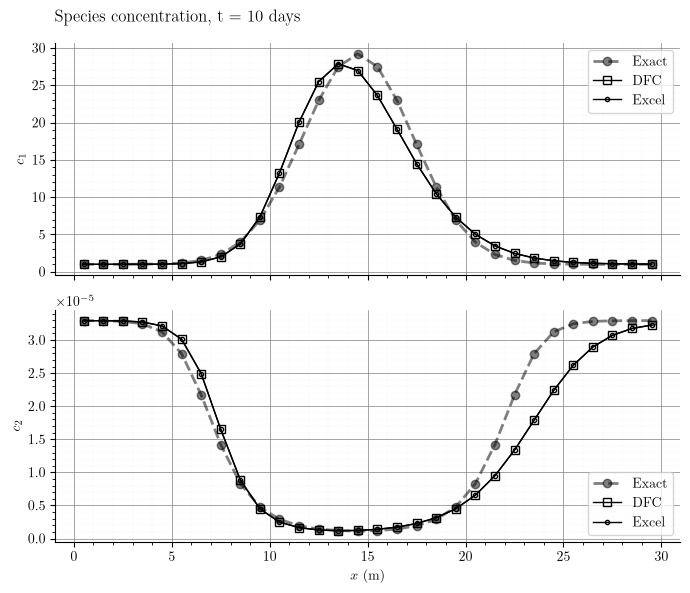

In [15]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(7,6))
plt.suptitle("Species concentration, t = $10$ days", x=0.085, ha="left")

## ---> Gráfica de la especie c1
ax[0].plot(x[0], an_c1, "o--", c = "black", lw=2.0, alpha=0.5, label="Exact", zorder=4)
ax[0].plot(x[0], c_dfc[0], "s-", c = "black", mec = "black", mfc="None", lw = 1.0, label="DFC", zorder=5)
ax[0].plot(x[0], c1, ".-", c = "black", mec = "black", mfc="None", lw = 1.0,label="Excel", zorder=5)
ax[0].set_ylabel("$c_1$")
ax[0].minorticks_on()
ax[0].grid(True, which='minor', color='gainsboro', lw = 0.05, zorder=2)
ax[0].grid(True,which='major', color='gray', lw = 0.5, zorder=3)
ax[0].legend()
ax[0].spines.right.set_visible(False)
ax[0].spines.top.set_visible(False)

## ---> Gráfica de la especie c2
ax[1].plot(x[0], an_c2, "o--", c = "black", lw=2.0, alpha=0.5, label="Exact", zorder=4)
ax[1].plot(x[0], c_dfc[1], "s-", c = "black", mec = "black", mfc="None", lw = 1.0, label="DFC", zorder=5)
ax[1].plot(x[0], c2, ".-", c = "black", mec = "black", mfc="None", lw = 1.0, label="Excel", zorder=5)
ax[1].set_xlabel("$x$ (m)")
ax[1].set_ylabel("$c_2$")
ax[1].minorticks_on()
ax[1].grid(True, which='minor', color='gainsboro', lw = 0.05, zorder=2)
ax[1].grid(True,which='major', color='gray', lw = 0.5, zorder=3)
ax[1].legend(loc="lower right")
ax[1].spines.right.set_visible(False)
ax[1].spines.top.set_visible(False)

plt.tight_layout()
plt.show()